# 20 · Agent discovery: finding an agent without hard-coding it
Level L4 · Part 4 · core · ~25 min · builds on 19

## Goal
Find agents at run time. Three ways are shown: an address written into the code, an address read from a config file, and a card found at a
known place (`/.well-known/agent-card.json`). Then the caller resolves two agents, reads their cards, and picks the one with the skill it needs.
This lesson makes no model call; the agents are local folders, so the discovery is what gets tested.

## Why it matters
A caller that hard-codes an agent's address breaks when the address changes, and it cannot find a new agent that offers a skill it needs. A
config file moves the address out of the code, but someone still has to edit it. Discovery means the caller asks a known place for the card,
and reads what is there.

| Hard-coded | From config | Discovered |
|---|---|---|
| The address is in the code | The address is in a file | The address is the agent's base; the card is at a known path |
| A new skill needs a code change | A new skill needs a config edit | A new skill appears in the card; the caller matches on it |
| A moved agent breaks every caller | A moved agent needs the file updated | A moved agent keeps its card, at its new base |

**What it makes easy:** a caller that finds an agent by what it can do. **When you don't need it:** one agent, one caller, one address that
never changes.

## The idea
Discovery is two steps. **Resolve**: from a base address, fetch the card at the well-known path. **Match**: read the card's skills and choose the
agent whose skill fits the request. The card is the only thing the caller trusts before it calls the agent.

## Picture
The diagram below is drawn by `show_mermaid`, a helper in `graph_view.py` (in the topic folder) that renders Mermaid text as a picture.

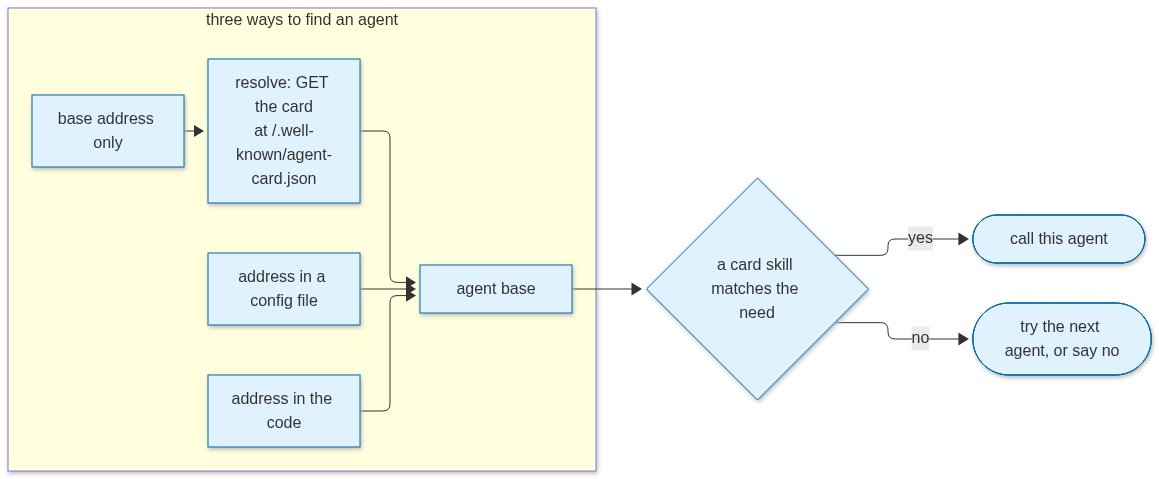

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph W["three ways to find an agent"]
    H["address in the code"] --> A["agent base"]
    F["address in a config file"] --> A
    D["base address only"] --> R["resolve: GET the card<br/>at /.well-known/agent-card.json"] --> A
  end
  A --> M{"a card skill matches the need"}
  M -->|yes| C(["call this agent"])
  M -->|no| N(["try the next agent, or say no"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  class H,F,D,R,A,M,C,N code
""")

## Step by step
Four short steps. Each one prints what it found, so you can check the output against the text.

**Step 1 · two agents, published as folders (no call).** Each agent has a folder with a card at `.well-known/agent-card.json`. A real agent
serves that file over HTTP; here it is a file, so the lesson runs offline. The two agents offer different skills: one answers order questions,
one answers policy questions.

In [2]:
import json
from pathlib import Path

ROOT = Path("../../../data/lg20/agents")
CARDS = {
    "orders-agent": {"name": "orders-agent", "description": "Order status and delivery questions.",
                     "skills": [{"id": "order_status", "description": "Status of one order.", "input": {"order_id": "string"}}],
                     "auth": "none"},
    "policy-agent": {"name": "policy-agent", "description": "Refund, return and delivery policy.",
                     "skills": [{"id": "policy_answer", "description": "Answer a policy question.", "input": {"topic": "string"}}],
                     "auth": "none"},
}
for name, card in CARDS.items():
    (ROOT / name / ".well-known").mkdir(parents=True, exist_ok=True)
    (ROOT / name / ".well-known" / "agent-card.json").write_text(json.dumps(card, indent=2))
print("published:", sorted(CARDS))

published: ['orders-agent', 'policy-agent']


**Step 2 · the three ways (no call).** The first two find the agent by an address they already know. The third starts from a base address
and reads the card at the well-known path, so the caller learns the skills before it sends anything.

In [3]:
HARD_CODED = ROOT / "orders-agent"  # 1. the address is written into the code


def from_config(config: dict, name: str) -> Path:  # 2. the address comes from a config file
    return ROOT / config["agents"][name]


def resolve(base: Path) -> dict:  # 3. the base address is enough: the card is at the well-known path
    return json.loads((base / ".well-known" / "agent-card.json").read_text())


CONFIG = {"agents": {"orders-agent": "orders-agent"}}
print("hard-coded card:", resolve(HARD_CODED)["name"])
print("from config:    ", resolve(from_config(CONFIG, "orders-agent"))["name"])
print("discovered:     ", [resolve(ROOT / name)["name"] for name in ("orders-agent", "policy-agent")])

hard-coded card: orders-agent
from config:     orders-agent
discovered:      ['orders-agent', 'policy-agent']


**Step 3 · match the need to a skill (no call).** The caller has a need, a skill id and an input. It searches the cards it resolved and picks
the agent that offers the skill. If no agent offers it, the function returns `(None, None)` and the caller says so rather than guessing an address.

In [4]:
def find_agent(need: str, bases: list[Path]):
    for base in bases:
        card = resolve(base)
        for skill in card["skills"]:
            if skill["id"] == need:
                return card["name"], skill
    return None, None


bases = [ROOT / "orders-agent", ROOT / "policy-agent"]
print(find_agent("policy_answer", bases))
name, _ = find_agent("refund_order", bases)  # no agent offers it
print("refund_order:", name or "no agent offers it, so the caller says so")

('policy-agent', {'id': 'policy_answer', 'description': 'Answer a policy question.', 'input': {'topic': 'string'}})
refund_order: no agent offers it, so the caller says so


**Step 4 · a moved agent (no call).** An agent moves to a new folder. A caller that hard-codes the old address breaks; a caller that resolves the
base finds the card at the new place, as long as the base is kept up to date in one place.

In [5]:
moved = ROOT / "orders-agent-v2"
(moved / ".well-known").mkdir(parents=True, exist_ok=True)
(moved / ".well-known" / "agent-card.json").write_text(json.dumps(CARDS["orders-agent"] | {"name": "orders-agent-v2"}))
print("the new base resolves to:", resolve(moved)["name"])
try:
    resolve(ROOT / "orders-agent-old")  # the old address
except FileNotFoundError as error:
    print("the old address fails:", str(error).split(":")[0])

the new base resolves to: orders-agent-v2
the old address fails: [Errno 2] No such file or directory


## At work
- Teams publish each agent's card at a fixed path and keep the base address in the registry. A caller looks the agent up by skill, so a move
  is one registry update, not a code change in every caller → lesson 21 (registry).
- A card is a claim. Before a caller trusts a card, it checks the card is from the expected base, and does not send data to an unknown one →
  lesson 26 (A2A discovery).
- The caller's search by skill is also what an agent router does. Lesson 30 (supervisor and handoffs) covers routing work between agents.

## What just happened
- Step 2: the same card comes back from all three ways, so `orders-agent` is found by its address, by its config entry and by its base.
- Step 3: the skill `policy_answer` resolves to `policy-agent`; `refund_order` matches nothing, so the result is `(None, None)`.
- Step 4: the moved card resolves at `orders-agent-v2`, and the old address raises `FileNotFoundError` (`[Errno 2]`).

## Common mistakes
1. **Discovering by name only.** Names change; skills are what the caller needs. Match on the skill.
2. **Trusting any card at any address.** A card is data from whoever serves it. Check where it came from before you send data to it.
3. **No answer when nothing matches.** A caller with no matching skill should stop and say so, not pick an agent at random.

The cell below shows the real errors that mistakes 1 and 3 cause. It catches each one and prints only the error name and its first line.

In [6]:
try:
    {b.name: b for b in bases}["refund-agent"]  # mistake 1: looking up by a name that is not there
except KeyError as error:
    print(f"mistake 1: {type(error).__name__}: {str(error).splitlines()[0]}")
try:
    _, skill = find_agent("refund_order", bases)
    print(skill["id"])  # mistake 3: nothing matched, so there is no skill to read
except TypeError as error:
    print(f"mistake 3: {type(error).__name__}: {str(error).splitlines()[0]}")

mistake 1: KeyError: 'refund-agent'
mistake 3: TypeError: 'NoneType' object is not subscriptable


## Try it
Write `skills_of(bases)` that returns a dict mapping each agent name to its list of skill ids. Test it on `bases`. No model call is needed.

In [7]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [8]:
def skills_of(bases: list[Path]) -> dict[str, list[str]]:
    return {resolve(b)["name"]: [s["id"] for s in resolve(b)["skills"]] for b in bases}


print(skills_of(bases))  # {'orders-agent': ['order_status'], 'policy-agent': ['policy_answer']}

{'orders-agent': ['order_status'], 'policy-agent': ['policy_answer']}


## Key terms
- **Agent card** — a small JSON file that describes an agent: its name, its skills and its input shapes.
- **Base address** — the address a caller starts from; the card is found relative to it.
- **Well-known path** — the fixed place, `/.well-known/agent-card.json`, where an agent publishes its card.
- **Resolve** — fetch an agent's card from its base address.
- **Skill** — one thing an agent can do, with an id and an input.

## Recap
- An agent can be found by an address in the code, an address in a config file, or its card at a well-known path.
- Discovery resolves the card, then matches the need to a skill.
- A caller with no matching skill says so; a moved agent is found by its base, not by its old address.

**Interview:** "How does a caller find an agent that offers a skill it needs, without a hard-coded address?" Strong answer: "It starts from a
base address it trusts, fetches the agent's card from the well-known path, and matches the request to a skill in the card. If none matches, it
says so."